# Integrate (batch correct) single cell datasets with scanpy and harmony

This notebook demonstrates integration and batch correction of single-cell RNA-seq datasets using Scanpy and harmony-tools. Below, each section is preceded by a brief explanation of its function.

## load required packages
Imports Python libraries for single-cell analysis, plotting, and data handling.

In [ ]:
import scanpy as sc
from pathlib import Path
import anndata as ad
import re
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
from anndata import AnnData
from typing import Optional, Dict
import grthub_tools as gt


## set scanpy default display settings 
Configures verbosity and figure parameters for consistent plotting.

In [ ]:
sc.settings.verbosity = 1 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(vector_friendly=False, dpi=100, fontsize=10, dpi_save=300, figsize=(5,4), format='png')

Reads the processed single-cell data for analysis.

In [ ]:
combined_adata_path = "../output/scanpy/output-XETG00221__0069982__Aged_cohort__20251003__181018/combined_filtered_tables_harmony_integrated.h5ad"
batch_variable = "batch"
groupby_var = "condition"
group1_value = "treated"
group2_value = "control"


In [ ]:
slug = re.search(r'(.*)_harmony_integrated.h5ad', os.path.basename(combined_adata_path)).group(1)

In [15]:
combined_adata = sc.read_h5ad(combined_adata_path)

Shows a summary of the loaded data.

In [16]:
combined_adata.obs.batch.value_counts()

batch
control_4_area_1_adult        6333
heat_stress_1_area_1_aged     5789
heat_stress_2_area_1_aged     5520
control_4_area_1_aged         5288
heat_stress_4_area_1_aged     5268
heat_stress_1_area_1_adult    4933
control_1_area_1_adult        4393
control_2_area_1_aged         4142
heat_stress_2_area_1_adult    4031
heat_stress_4_area_1_adult    3937
control_2_area_1_adult        2617
heat_stress_3_area_1_aged     2235
control_3_area_1_adult        2189
heat_stress_3_area_1_adult    1964
control_3_area_1_aged         1906
control_1_area_1_aged         1854
Name: count, dtype: int64

### Visualization without batch correction

cells below copied from harmony-tools intro tutorial https://docs.harmony-tools.org/en/stable/tutorials/notebooks/quick_start/api_overview.html

<div class='alert alert-block alert-warning'> <b>Warning</b> We use UMAP to *qualitatively* assess our low-dimension embeddings of cells. We do not advise using UMAP or any similar approach quantitatively. We do recommend using the embeddings produced by harmony as a plug-in replacement of what you would get from PCA, as we show below. </div>

First, we demonstrate the presence of nuisance variation with respect to nuclei/whole cell, age group, and donor by plotting the UMAP results of the top 30 PCA components for the raw count data.

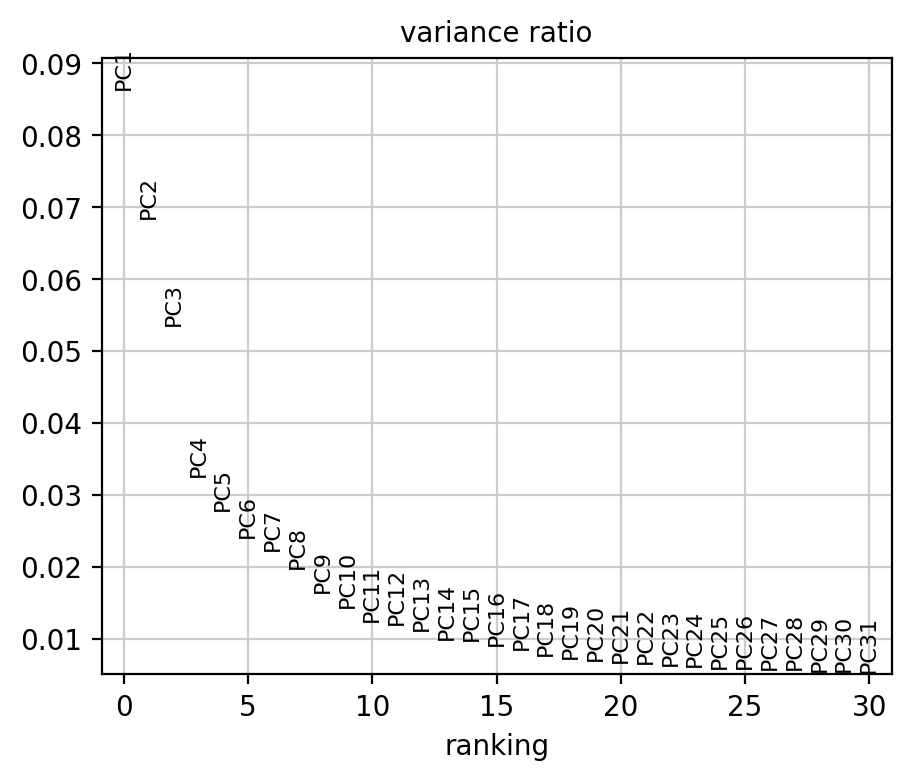

In [35]:
sc.pl.pca_variance_ratio(combined_adata, n_pcs=30)

In [17]:
# run PCA then generate UMAP plots
sc.tl.pca(combined_adata)
sc.pp.neighbors(combined_adata, n_pcs=30, n_neighbors=20)
sc.tl.umap(combined_adata, min_dist=0.3)

/data/homezvol1/kstachel/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


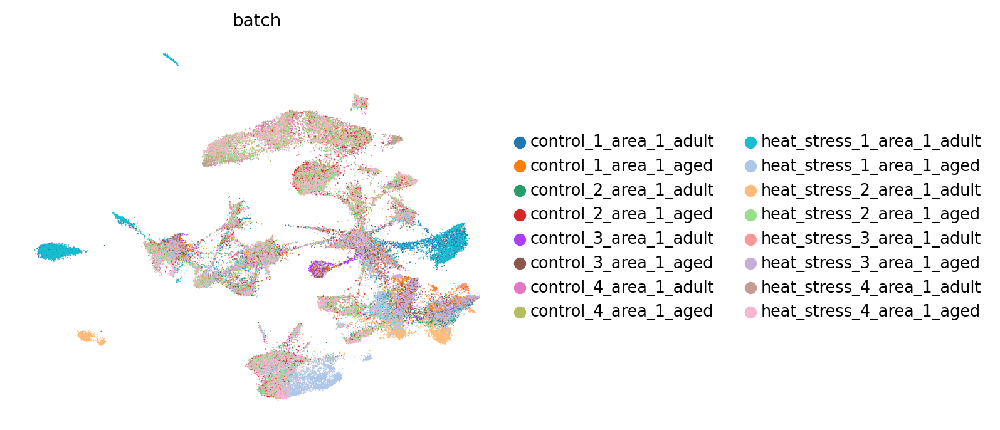

In [19]:
sc.pl.umap(
    combined_adata,
    color=[batch_variable],
    frameon=False,
)

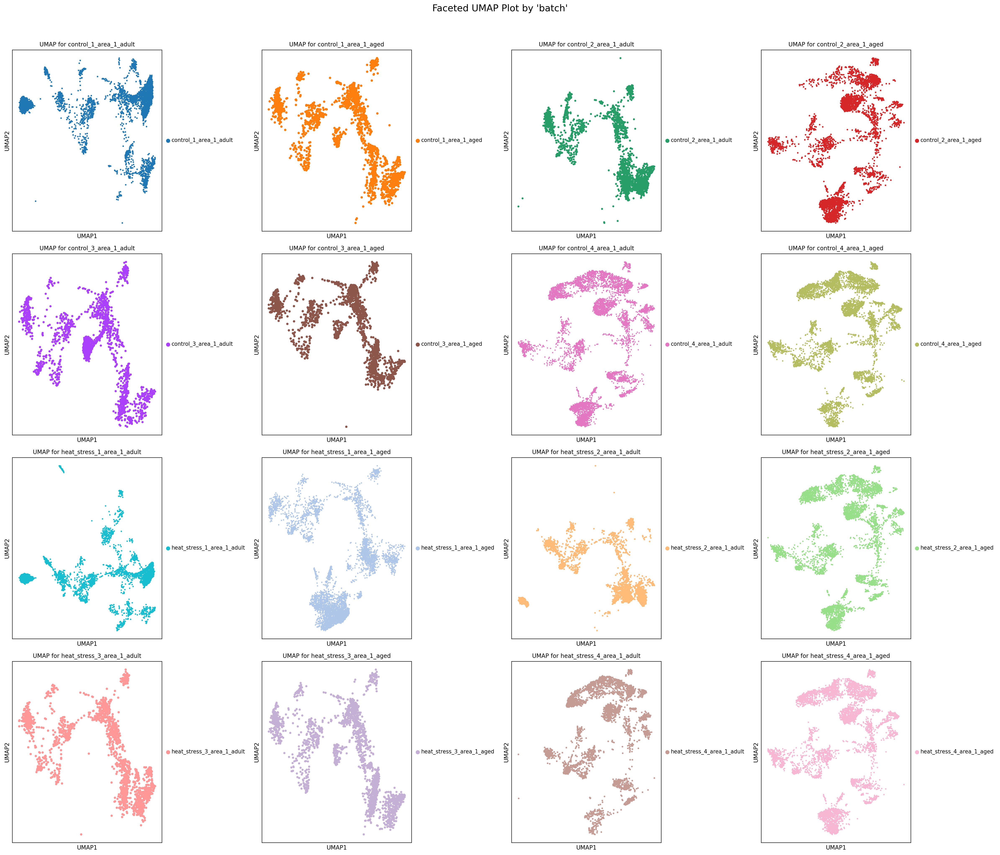

In [ ]:
gt.facet_umap_by_obs(
    combined_adata,
    batch_variable,
    coloring_variable=batch_variable
)

### Visualization with batch correction (harmony)

Now, let us try using the harmony latent space to generate the same UMAP plots to see if harmony successfully accounts for batch effects in the data.

In [21]:
combined_adata

AnnData object with n_obs × n_vars = 62399 × 247
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'polygon_id', 'sample_id', 'area', 'age', 'condition', 'batch', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden_harmony'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'leiden_harmony', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'umap', 'batch_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [22]:
combined_adata.obsm

AxisArrays with keys: X_pca, X_pca_harmony, X_umap, spatial

In [23]:
# use harmony latent space for UMAP generation
harmony_LATENT_KEY = "X_pca_harmony"
sc.pp.neighbors(combined_adata, use_rep=harmony_LATENT_KEY)
sc.tl.umap(combined_adata, min_dist=0.3)

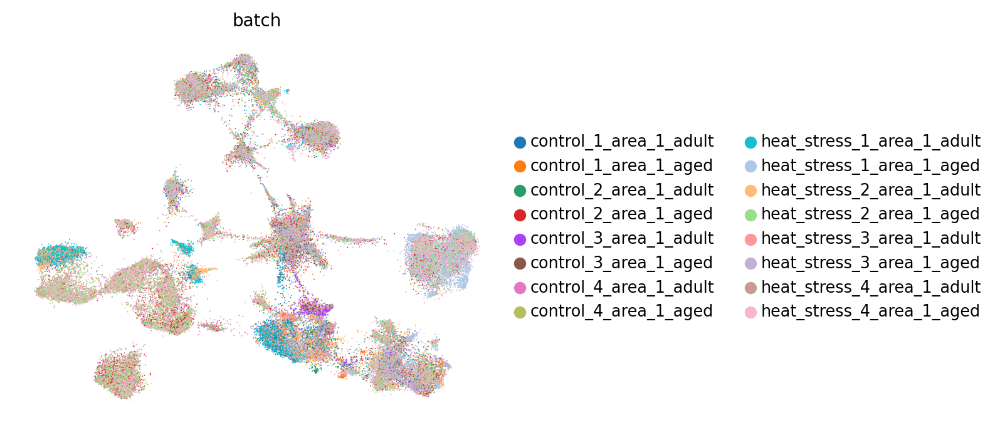

In [ ]:
sc.pl.umap(
    combined_adata,
    color=[batch_variable],
    frameon=False,
)


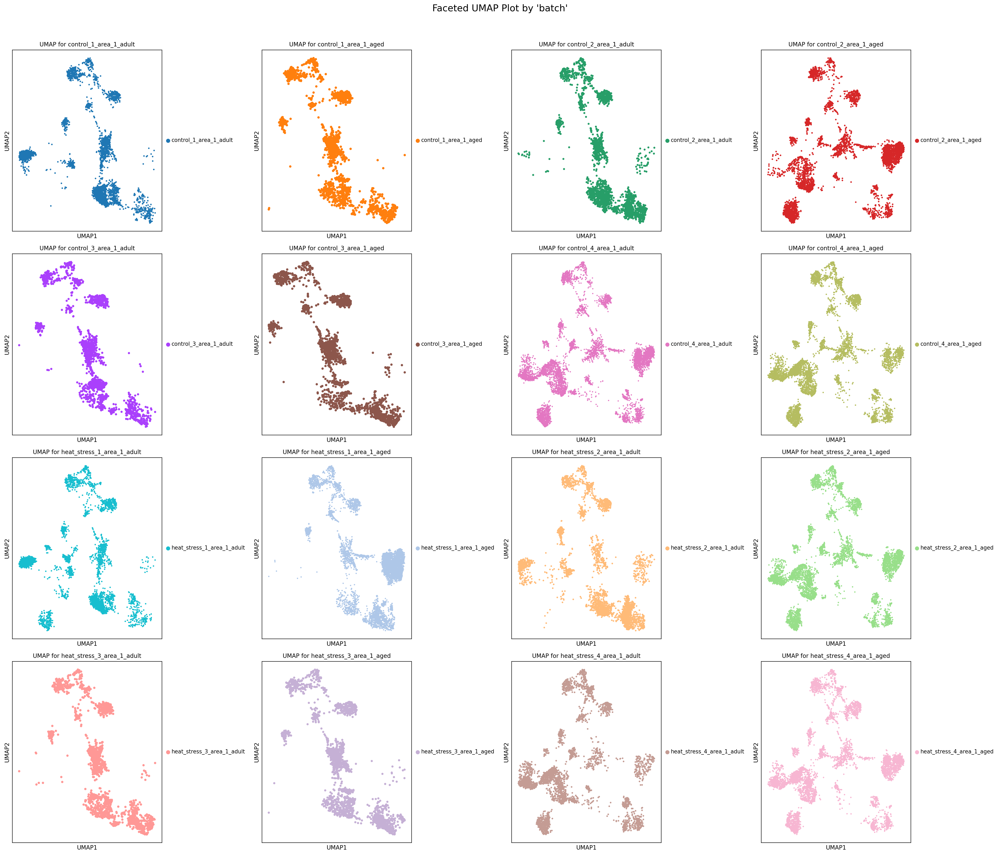

In [ ]:

gt.facet_umap_by_obs(
    combined_adata,
    batch_variable,
    coloring_variable=batch_variable
)

We can see that harmony was able to correct for nuisance variation due to nuclei/whole cell, age group, and donor, while maintaining separation of cell types.

### Clustering on the harmony latent space

The user will note that we imported curated labels from the original publication. Our interface with scanpy makes it easy to cluster the data with scanpy from harmony's latent space and then reinject them into harmony (e.g., for differential expression).

In [26]:
# neighbors were already computed using harmony
HARMONY_CLUSTERS_KEY = "leiden_harmony"
sc.tl.leiden(combined_adata, key_added=HARMONY_CLUSTERS_KEY, resolution=0.5)

/tmp/ipykernel_2683015/3563657767.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(combined_adata, key_added=HARMONY_CLUSTERS_KEY, resolution=0.5)


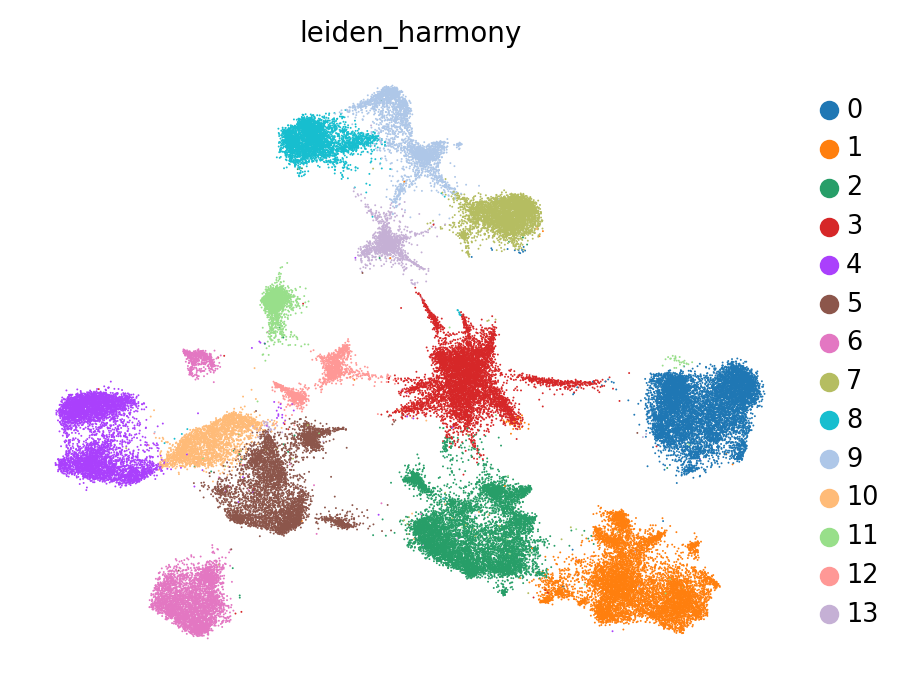

In [27]:
sc.pl.umap(
    combined_adata,
    color=[HARMONY_CLUSTERS_KEY],
    frameon=False,
)

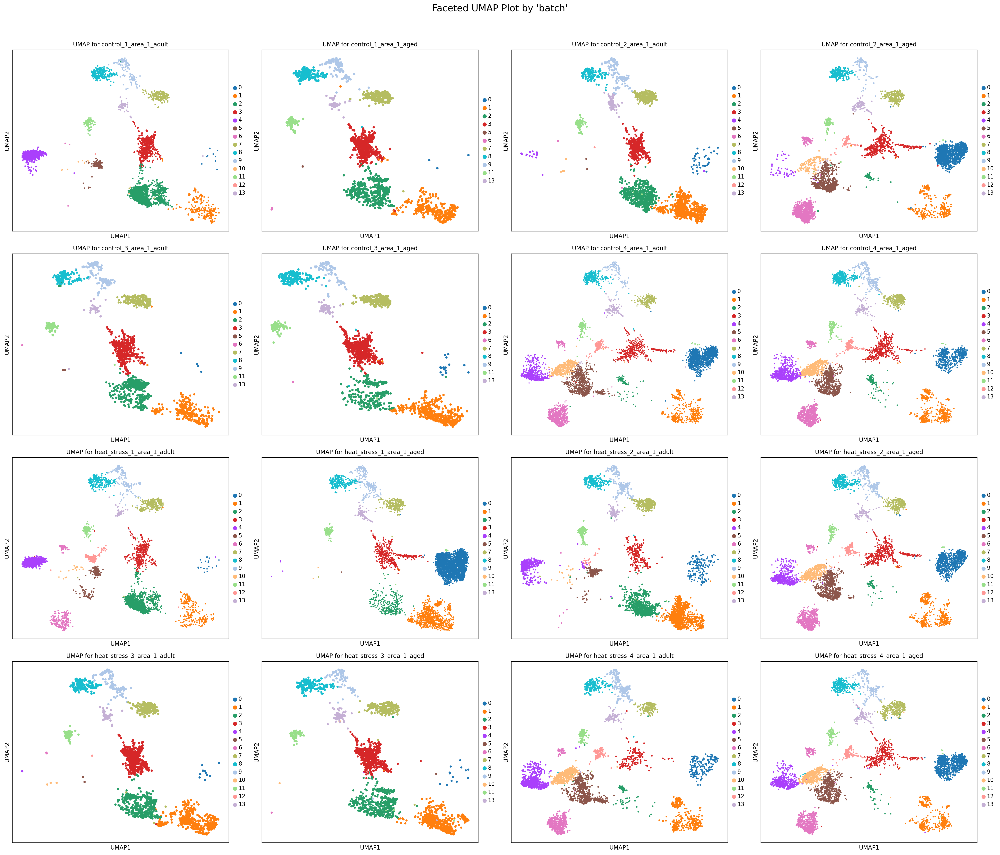

In [ ]:
gt.facet_umap_by_obs(
    combined_adata,
    batch_variable,
    coloring_variable=HARMONY_CLUSTERS_KEY
)

## Find marker genes for our integrated data using scanpy `rank_genes_groups`

In [29]:

# Find marker genes for each cluster
sc.tl.rank_genes_groups(combined_adata, HARMONY_CLUSTERS_KEY, method='wilcoxon')

#  Stacked Bar Plot of cluster membership by batch

## View the distribution of batches across clusters to get a sense of any sample-specific cell types/states

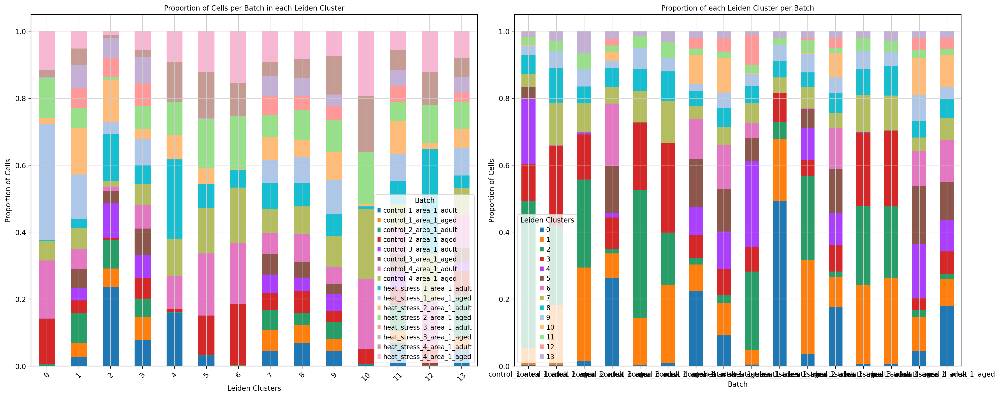

In [30]:
# Create the two cross-tabulation dataframes
crosstab_df_1 = pd.crosstab(combined_adata.obs[HARMONY_CLUSTERS_KEY], combined_adata.obs['batch'], normalize='index')
crosstab_df_2 = pd.crosstab(combined_adata.obs['batch'], combined_adata.obs[HARMONY_CLUSTERS_KEY], normalize='index')

# Set up the subplot figure and axes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), sharey=False) # Use sharey=True if you want the same y-axis scale

# Plot the first cross-tabulation on the first axis
crosstab_df_1.plot(kind='bar', stacked=True, ax=ax1)
ax1.set_title('Proportion of Cells per Batch in each Leiden Cluster')
ax1.set_xlabel('Leiden Clusters')
ax1.set_ylabel('Proportion of Cells')
ax1.legend(title='Batch')
ax1.tick_params(axis='x', rotation=45)

# Plot the second cross-tabulation on the second axis
crosstab_df_2.plot(kind='bar', stacked=True, ax=ax2)
ax2.set_title('Proportion of each Leiden Cluster per Batch')
ax2.set_xlabel('Batch')
ax2.set_ylabel('Proportion of Cells')
ax2.legend(title='Leiden Clusters')
ax2.tick_params(axis='x', rotation=0)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

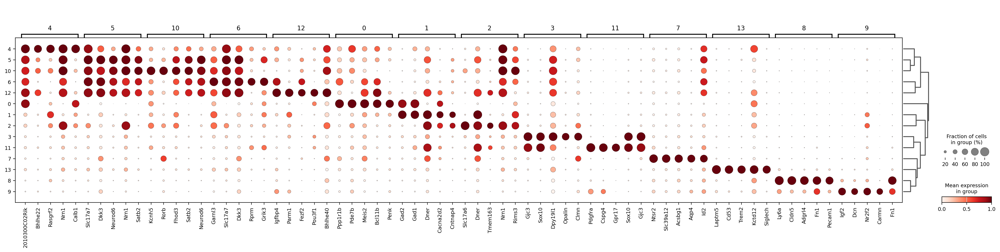

In [31]:
sc.pl.rank_genes_groups_dotplot(
    combined_adata, groupby=HARMONY_CLUSTERS_KEY, standard_scale="var", n_genes=5
)

In [32]:
# Create a copy to avoid modifying the original data
annotated_table = crosstab_df_1.copy()

# Add a 'Total' column for clarity
annotated_table['Total'] = annotated_table.sum(axis=1)

# Calculate and format percentages for each cell
for col in crosstab_df_1.columns:
    # Use f-strings to combine the count and the formatted percentage
    annotated_table[col] = crosstab_df_1.apply(
        lambda row: f"{row[col] / row.sum() * 100:.1f}%",
        axis=1
    )

annotated_table

batch,control_1_area_1_adult,control_1_area_1_aged,control_2_area_1_adult,control_2_area_1_aged,control_3_area_1_adult,control_3_area_1_aged,control_4_area_1_adult,control_4_area_1_aged,heat_stress_1_area_1_adult,heat_stress_1_area_1_aged,heat_stress_2_area_1_adult,heat_stress_2_area_1_aged,heat_stress_3_area_1_adult,heat_stress_3_area_1_aged,heat_stress_4_area_1_adult,heat_stress_4_area_1_aged,Total
leiden_harmony,,,,,,,,,,,,,,,,,
0,0.1%,0.0%,0.5%,13.3%,0.0%,0.2%,17.3%,5.9%,0.2%,34.8%,1.8%,11.9%,0.1%,0.2%,2.2%,11.5%,1.0
1,2.8%,4.1%,9.0%,3.7%,3.8%,5.5%,6.1%,6.3%,2.7%,13.2%,13.9%,6.1%,5.7%,7.1%,4.9%,5.2%,1.0
2,23.7%,5.4%,8.5%,0.7%,10.3%,3.6%,1.4%,1.6%,14.2%,3.6%,12.4%,1.0%,5.7%,5.9%,1.0%,1.0%,1.0
3,7.7%,6.9%,5.5%,6.1%,6.9%,8.0%,6.9%,6.4%,5.6%,7.8%,3.1%,6.8%,6.7%,7.9%,2.2%,5.5%,1.0
4,15.9%,0.0%,0.3%,0.9%,0.0%,0.0%,9.9%,11.1%,23.6%,0.1%,7.2%,10.0%,0.0%,0.0%,11.8%,9.3%,1.0
5,3.1%,0.0%,0.0%,11.9%,0.0%,0.0%,18.6%,13.6%,7.0%,0.0%,4.7%,14.9%,0.0%,0.0%,13.8%,12.2%,1.0
6,0.1%,0.0%,0.0%,18.4%,0.0%,0.0%,18.0%,16.7%,5.2%,0.0%,0.2%,15.9%,0.0%,0.0%,9.8%,15.5%,1.0
7,4.6%,6.1%,5.9%,5.3%,5.3%,6.2%,6.2%,7.3%,7.7%,7.0%,6.7%,6.7%,5.6%,6.1%,4.1%,9.1%,1.0
8,6.9%,5.3%,3.6%,6.6%,4.0%,4.7%,8.2%,8.3%,6.9%,8.0%,4.9%,9.0%,4.2%,5.5%,5.5%,8.4%,1.0


# Export processed anndata object with harmony embeddings and cluster labels

In [ ]:
combined_adata.write_h5ad(f"output/scanpy/{slug}_harmony_integrated_processed.h5ad")

In [ ]:
# Access the marker genes
marker_genes_df = sc.get.rank_genes_groups_df(combined_adata, group=None)
marker_genes_df.to_csv(f"results/{slug}_marker_genes_per_cluster.csv")

In [ ]:
# compare 'treated' vs 'control' within each 'leiden' cluster
res = gt.rank_genes_groups_within_clusters(
    combined_adata,
    groupby=groupby_var,
    cluster_key="leiden_harmony",
    group1=group1_value,
    group2=group2_value,
    key_prefix="rgg_condition_vs_control"
)


/tmp/ipykernel_2683015/4253405084.py:60: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  clusters = pd.Categorical(adata.obs[cluster_key]).categories if pd.api.types.is_categorical_dtype(adata.obs[cluster_key]) else np.unique(adata.obs[cluster_key].astype(str))


In [ ]:
combined_adata.obs.value_counts(subset=[groupby_var, "leiden_harmony"])

In [ ]:
out_path = f"results/{slug}_{groupby_var}_ranked_genes_per_cluster.xlsx"
with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
    for sheet_name, df in res.items():
        # Excel sheet names are max 31 chars; sanitize if needed
        safe_name = str(sheet_name)[:31]
        df.to_excel(writer, sheet_name=safe_name, index=False)
# file closed & written

dict_keys(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13'])

## Computation of spatial statistics 

This example shows how to compute centrality scores, given a spatial graph and cell type annotation.

The scores calculated are closeness centrality, degree centrality and clustering coefficient with the following properties:

- closeness centrality - measure of how close the group is to other nodes.
- clustering coefficient - measure of the degree to which nodes cluster together.
- degree centrality - fraction of non-group members connected to group members.

All scores are descriptive statistics of the spatial graph.

This dataset contains Leiden cluster groups’ annotations in `adata.obs`, which are used for calculation of centrality scores.

### Building a spatial neighborhood graph

First, we need to compute a connectivity matrix from spatial coordinates to calculate the centrality scores. We can use `squidpy.gr.spatial_neighbors` for this purpose. We use the `coord_type="generic"` based on the data and the neighbors are classified with Delaunay triangulation by specifying `delaunay=True`.

In [ ]:
sq.gr.spatial_neighbors(combined_adata, coord_type="generic", delaunay=True)

### Compute centrality scores 

Centrality scores are calculated with `squidpy.gr.centrality_scores`, with the Leiden groups as clusters.

In [ ]:
sq.gr.centrality_scores(combined_adata, cluster_key="leiden_harmony")

The results were visualized by plotting the average centrality, closeness centrality, and degree centrality using `squidpy.pl.centrality_scores`.

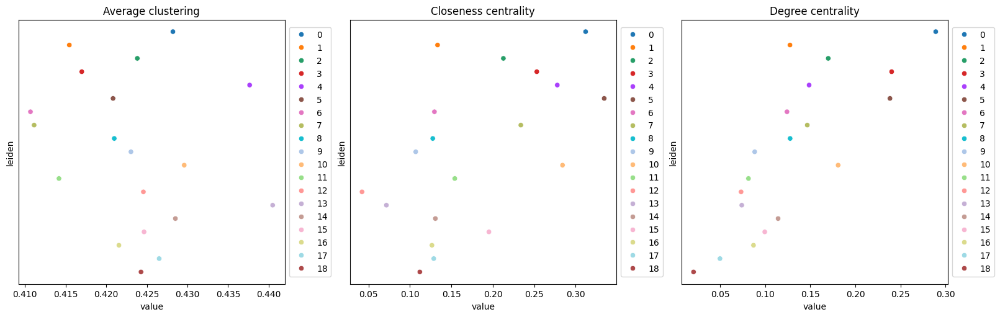

In [ ]:
sq.pl.centrality_scores(combined_adata, cluster_key="leiden_harmony", figsize=(16, 5))

### Compute co-occurrence probability 

This example shows how to compute the co-occurrence probability.

The co-occurrence score is defined as:

$\frac{p(exp|cond)}{p(exp)}$

where $p(exp|cond)$ is the conditional probability of observing a cluster $exp$ conditioned on the presence of a cluster $cond$, whereas $p(exp)$ is the probability of observing $exp$ in the radius size of interest. The score is computed across increasing radii size around each cell in the tissue.

We can compute the co-occurrence score with `squidpy.gr.co_occurrence`. Results of co-occurrence probability ratio can be visualized with `squidpy.pl.co_occurrence`. The ‘3’ in the $\frac{p(exp|cond)}{p(exp)}$ represents a Leiden clustered group.

We can further visualize tissue organization in spatial coordinates with `squidpy.pl.spatial_scatter`, with an overlay of the expressed genes which were colored in consonance with the Leiden clusters.

First we create a new table, which is a subset of the original Anndata object, and store it in tables.

In [ ]:
adata_subsample = sc.pp.subsample(combined_adata, fraction=0.5, copy=True)

  0%|          | 0/780 [00:00<?, ?/s]

100%|██████████| 780/780 [17:39<00:00,  1.36s/]


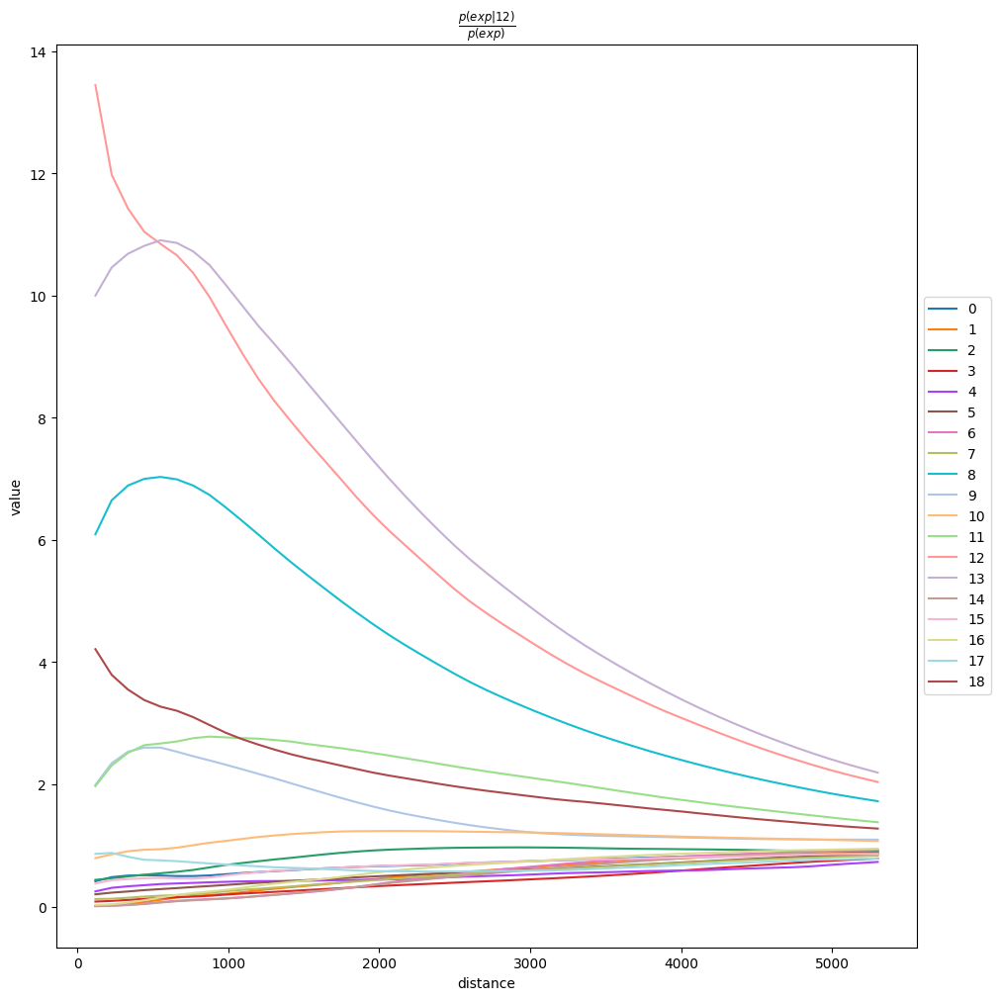

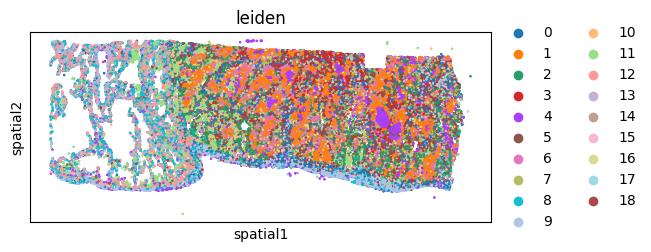

In [ ]:
sq.gr.co_occurrence(
    adata_subsample,
    cluster_key="leiden_harmony",
)
sq.pl.co_occurrence(
    adata_subsample,
    cluster_key="leiden_harmony",
    clusters="12",
    figsize=(10, 10),
)
sq.pl.spatial_scatter(
    adata_subsample,
    color="leiden_harmony",
    shape=None,
    size=2,
)

### Neighbors enrichment analysis 


This example shows how to run the neighbors enrichment analysis routine.

It calculates an enrichment score based on proximity on the connectivity graph of cell clusters. The number of observed events is compared against  permutations and a z-score is computed.

This dataset contains cell type annotations in `adata.obs` which are used for calculation of the neighborhood enrichment. We calculate the neighborhood enrichment score with `squidpy.gr.nhood_enrichment`.

In [ ]:
sq.gr.nhood_enrichment(combined_adata, cluster_key="leiden_harmony")

100%|██████████| 1000/1000 [00:21<00:00, 46.11/s]


And visualize the results with `squidpy.pl.nhood_enrichment`.

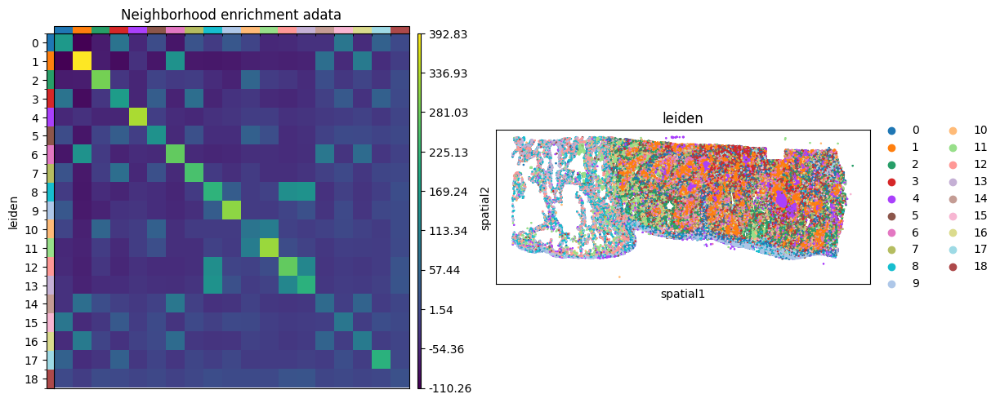

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
sq.pl.nhood_enrichment(
    combined_adata,
    cluster_key="leiden_harmony",
    figsize=(8, 8),
    title="Neighborhood enrichment adata",
    ax=ax[0],
)
sq.pl.spatial_scatter(adata_subsample, color="leiden", shape=None, size=2, ax=ax[1])

### Compute Moran's I score 


This example shows how to compute the Moran’s I global spatial auto-correlation statistics.

The Moran’s I global spatial auto-correlation statistics evaluates whether features (i.e. genes) shows a pattern that is clustered, dispersed or random in the tissue are under consideration.

We can compute the Moran’s I score with `squidpy.gr.spatial_autocorr` and mode = 'moran'. We first need to compute a spatial graph with `squidpy.gr.spatial_neighbors`. We will also subset the number of genes to evaluate.

In [ ]:
sq.gr.spatial_neighbors(adata_subsample, coord_type="generic", delaunay=True)
sq.gr.spatial_autocorr(
    adata_subsample,
    mode="moran",
    n_perms=100,
    n_jobs=1,
)
adata_subsample.uns["moranI"].head(10)

100%|██████████| 100/100 [05:49<00:00,  3.49s/]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
AREG,0.695981,0.0,0.000004,0.0,0.009901,0.000009,0.0,0.0,0.009984
MET,0.683335,0.0,0.000004,0.0,0.009901,0.000010,0.0,0.0,0.009984
ANXA1,0.666874,0.0,0.000004,0.0,0.009901,0.000009,0.0,0.0,0.009984
EPCAM,0.633024,0.0,0.000004,0.0,0.009901,0.000007,0.0,0.0,0.009984
DMBT1,0.587696,0.0,0.000004,0.0,0.009901,0.000009,0.0,0.0,0.009984
IGKC,0.549282,0.0,0.000004,0.0,0.009901,0.000006,0.0,0.0,0.009984
IGHG1,0.518234,0.0,0.000004,0.0,0.009901,0.000006,0.0,0.0,0.009984
IDO1,0.496409,0.0,0.000004,0.0,0.009901,0.000006,0.0,0.0,0.009984
SPARC,0.445792,0.0,0.000004,0.0,0.009901,0.000005,0.0,0.0,0.009984
APOE,0.437499,0.0,0.000004,0.0,0.009901,0.000008,0.0,0.0,0.009984


We can visualize some of those genes with `squidpy.pl.spatial_scatter`. We could also pass `mode = 'geary'` to compute a closely related auto-correlation statistic, Geary’s C. See `squidpy.gr.spatial_autocorr` for more information.

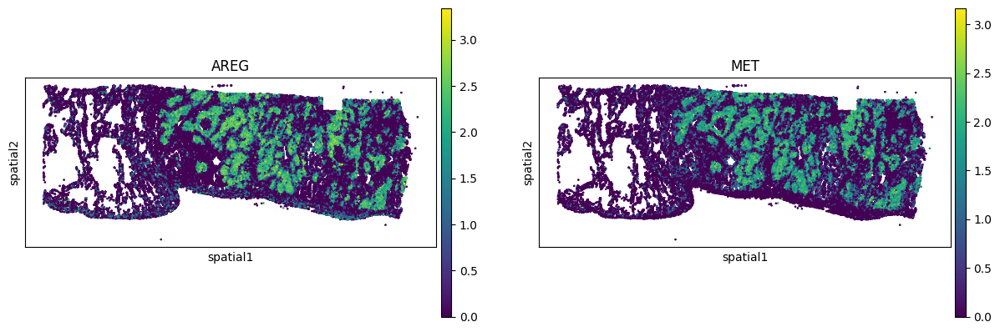

In [ ]:
sq.pl.spatial_scatter(
    adata_subsample,
    library_id="spatial",
    color=[
        "AREG",
        "MET",
    ],
    shape=None,
    size=2,
    img=False,
)